<a href="https://colab.research.google.com/github/jojojojo-jo/LRP_analysis_resnet/blob/main/LRP_heatmap_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#0. Import

LRP scripts: https://github.com/kaifishr/PyTorchRelevancePropagation

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F

from PIL import Image

import os
import numpy as np

import torchvision
from torchvision import models, transforms

#import torchinfo.summary
try:
  from torchinfo import summary
except:
  print("[INFO] Couldn't find torchinfo... installing it")
  !pip install -q torchinfo
  from torchinfo import summary

#import helper functions
try:
  from going_modular.going_modular import data_setup, engine
except:
  print(f"[INFO] Couldn't find going_modular scripts... downloading from GitHub")
  !git clone https://github.com/mrdbourke/pytorch-deep-learning
  !mv pytorch-deep-learning/going_modular .
  !rm -rf pytorch-deep-learning
  from going_modular.going_modular import data_setup, engine

#import lrp scripts
try:
    from src import lrp
except:
    print("[INFO] Couldn't find LRP scripts... downloading them from GitHub.")
    !git clone https://github.com/kaifishr/PyTorchRelevancePropagation
    !mv PyTorchRelevancePropagation/src .
    !rm -rf PyTorchRelevancePropagation
    from src import lrp

[INFO] Couldn't find torchinfo... installing it
[INFO] Couldn't find going_modular scripts... downloading from GitHub
Cloning into 'pytorch-deep-learning'...
remote: Enumerating objects: 4410, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 4410 (delta 5), reused 2 (delta 2), pack-reused 4399 (from 2)
Receiving objects: 100% (4410/4410), 764.18 MiB | 23.05 MiB/s, done.
Resolving deltas: 100% (2661/2661), done.
Updating files: 100% (248/248), done.
[INFO] Couldn't find LRP scripts... downloading them from GitHub.
Cloning into 'PyTorchRelevancePropagation'...
remote: Enumerating objects: 159, done.
remote: Counting objects: 100% (119/119), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 159 (delta 44), reused 102 (delta 34), pack-reused 40 (from 1)
Receiving objects: 100% (159/159), 16.45 MiB | 20.27 MiB/s, done.
Resolving deltas: 100% (44/44), done.


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

#1. Get data

In [ ]:
import os
import zipfile

from pathlib import Path

import requests

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

if image_path.is_dir():
  print(f"{image_path} directory exists")
else:
  print(f"Did not find {image_path} directory, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

  with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print("Downloading data...")
    f.write(request.content)

  with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
    print("Unzipping data...")
    zip_ref.extractall(image_path)

  os.remove(data_path / "pizza_steak_sushi.zip")

Did not find data/pizza_steak_sushi directory, creating one...
Unzipping data...


In [ ]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [ ]:
weights = torchvision.models.ResNet18_Weights.DEFAULT
auto_transforms = weights.transforms()
print(f"Automatically created transforms: {auto_transforms}")

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms,
                                                                               batch_size=32)
train_dataloader, test_dataloader, class_names

Automatically created transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


(<torch.utils.data.dataloader.DataLoader at 0x7c385e440110>,
 ['pizza', 'steak', 'sushi'])

#2. Load trained model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model = models.resnet18(weights=weights)

model.fc = nn.Linear(model.fc.in_features, len(class_names))

model_path = '/content/drive/MyDrive/study/Project/ResNet18_model.pth'
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model = model.to(device)

model.eval()

print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Model loaded successfully!


#3. Generate LRP Heatmaps

In [ ]:
!rm -rf output
!rm -rf data/.ipynb_checkpoints

In [ ]:
import argparse
import pathlib

# Assuming 'projects' directory is at the root level /content/projects
# and 'main' function is within 'main.py' inside 'per_image_lrp' sub-directory.
# We explicitly import the 'main' function.
try:
  from projects.per_image_lrp.main import per_image_lrp
except:
    print("[INFO] Couldn't find LRP scripts... downloading them from GitHub.")
    !git clone https://github.com/kaifishr/PyTorchRelevancePropagation
    !mv PyTorchRelevancePropagation/projects .
    !rm -rf PyTorchRelevancePropagation
    from projects.per_image_lrp.main import per_image_lrp

# 1. Create a manual configuration
config = argparse.Namespace(
    input_dir="data",        #folder name
    output_dir="./output",   # Where heatmaps will go
    batch_size=1,            # Plotting only supports 1
    device="gpu",            # Use "gpu" if you have a CUDA device
    top_k=0.15,                 # Filters out low-relevance noise
    resize=224               # Standard VGG input size
)

# 2. Create the output folder
pathlib.Path(config.output_dir).mkdir(parents=True, exist_ok=True)

# 3. Run the function
per_image_lrp(config)

Using: cuda

15.20 FPS
16.25 FPS
16.30 FPS
16.28 FPS
16.26 FPS
14.30 FPS
14.29 FPS
14.29 FPS
14.28 FPS
14.32 FPS
14.24 FPS
14.30 FPS
14.30 FPS
14.31 FPS
14.33 FPS
14.32 FPS
14.32 FPS
14.31 FPS
14.30 FPS
14.28 FPS
14.31 FPS
14.32 FPS
14.30 FPS
14.30 FPS
14.31 FPS
14.29 FPS
14.26 FPS
14.26 FPS
14.27 FPS
14.30 FPS
14.31 FPS
14.30 FPS
14.29 FPS
14.27 FPS
14.28 FPS
14.30 FPS
14.31 FPS
14.27 FPS
14.31 FPS
14.27 FPS
14.30 FPS
14.31 FPS
14.27 FPS
14.25 FPS
14.31 FPS
14.27 FPS
14.27 FPS
14.29 FPS
14.28 FPS
14.24 FPS
14.29 FPS
14.29 FPS
14.25 FPS
14.28 FPS
14.31 FPS
14.32 FPS
14.30 FPS
14.26 FPS
14.27 FPS
14.28 FPS
14.32 FPS
14.27 FPS
14.30 FPS
14.27 FPS
14.29 FPS
14.29 FPS
14.29 FPS
14.31 FPS
14.27 FPS
14.30 FPS
14.31 FPS
14.27 FPS
14.27 FPS
14.30 FPS
14.29 FPS
14.27 FPS
14.30 FPS
14.29 FPS
14.32 FPS
14.29 FPS
14.27 FPS
14.31 FPS
14.30 FPS
14.32 FPS
14.30 FPS
14.31 FPS
14.33 FPS
14.33 FPS
14.28 FPS
14.29 FPS
14.30 FPS
14.29 FPS
14.27 FPS
14.33 FPS
14.32 FPS
14.28 FPS
14.30 FPS
14.31 FPS
14.29 F

#4. Check random outputs

[254, 285, 174, 30, 109, 91, 139, 278, 214, 2]
Displaying: ./output/image_254.png


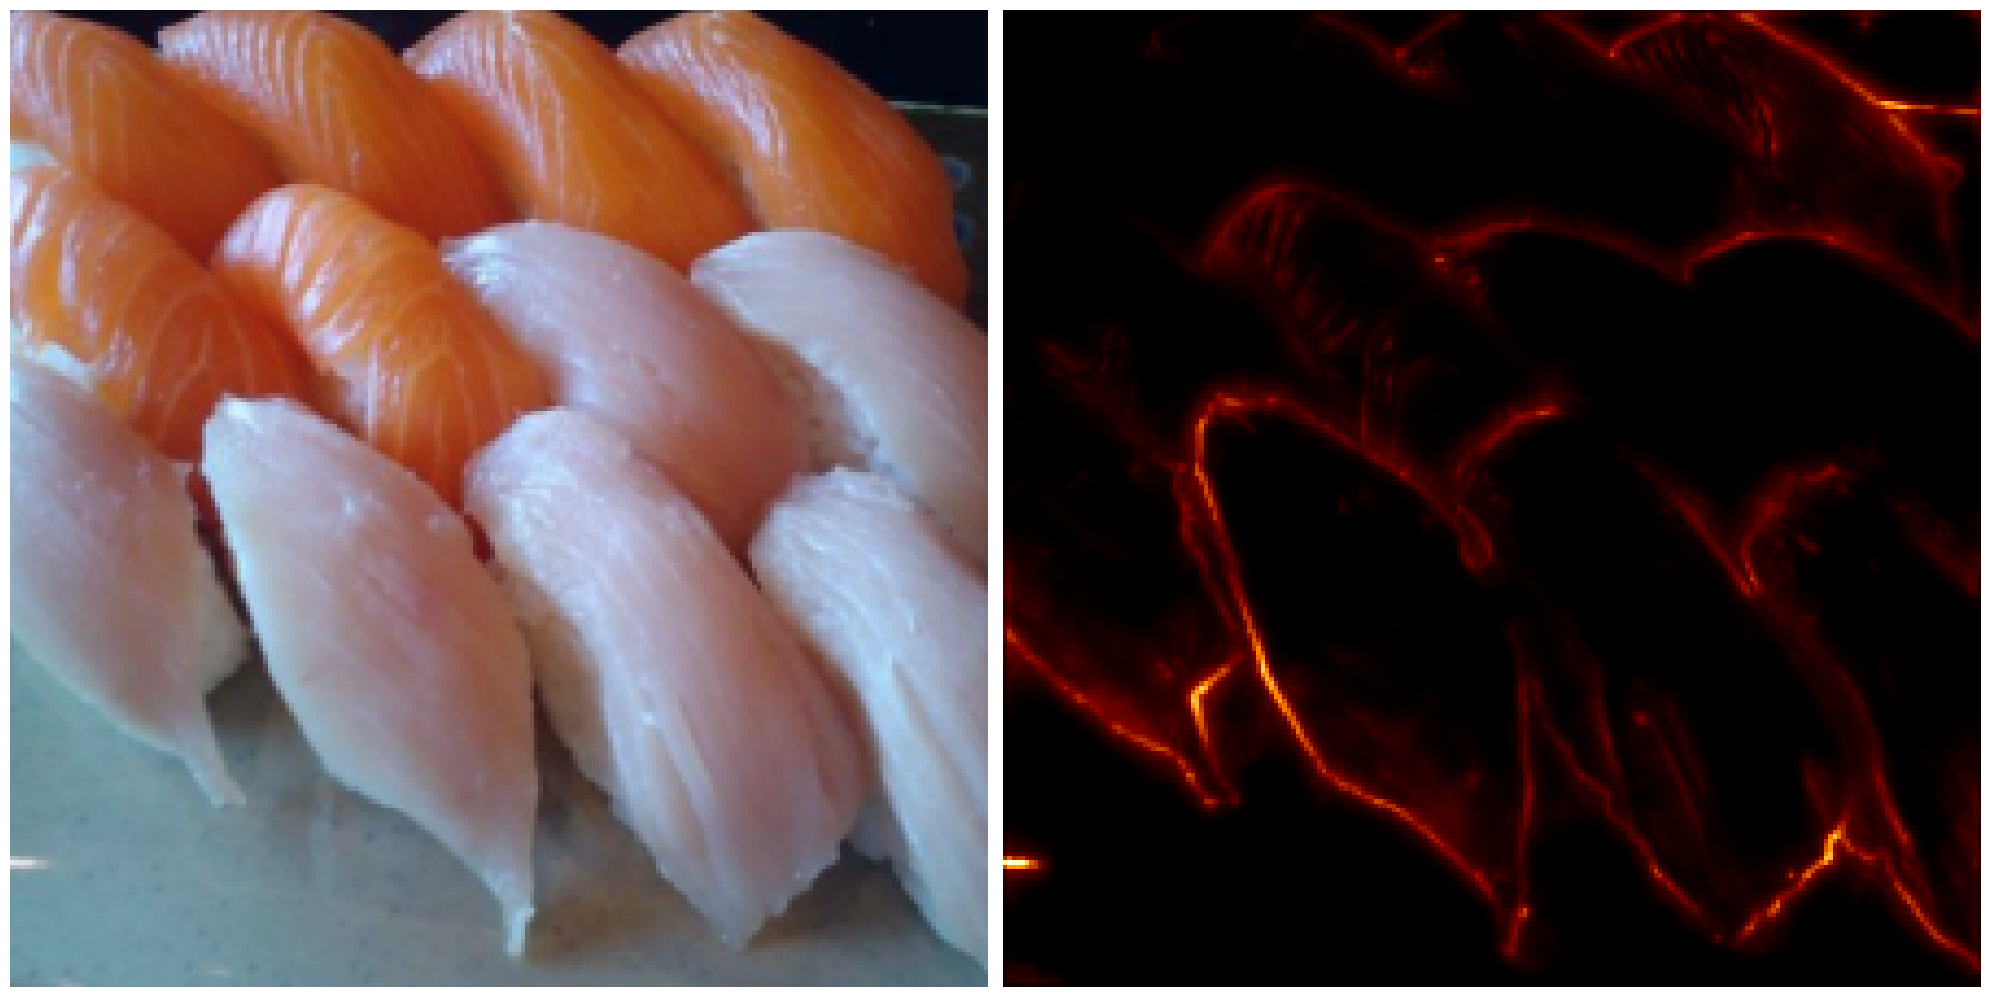

Displaying: ./output/image_285.png


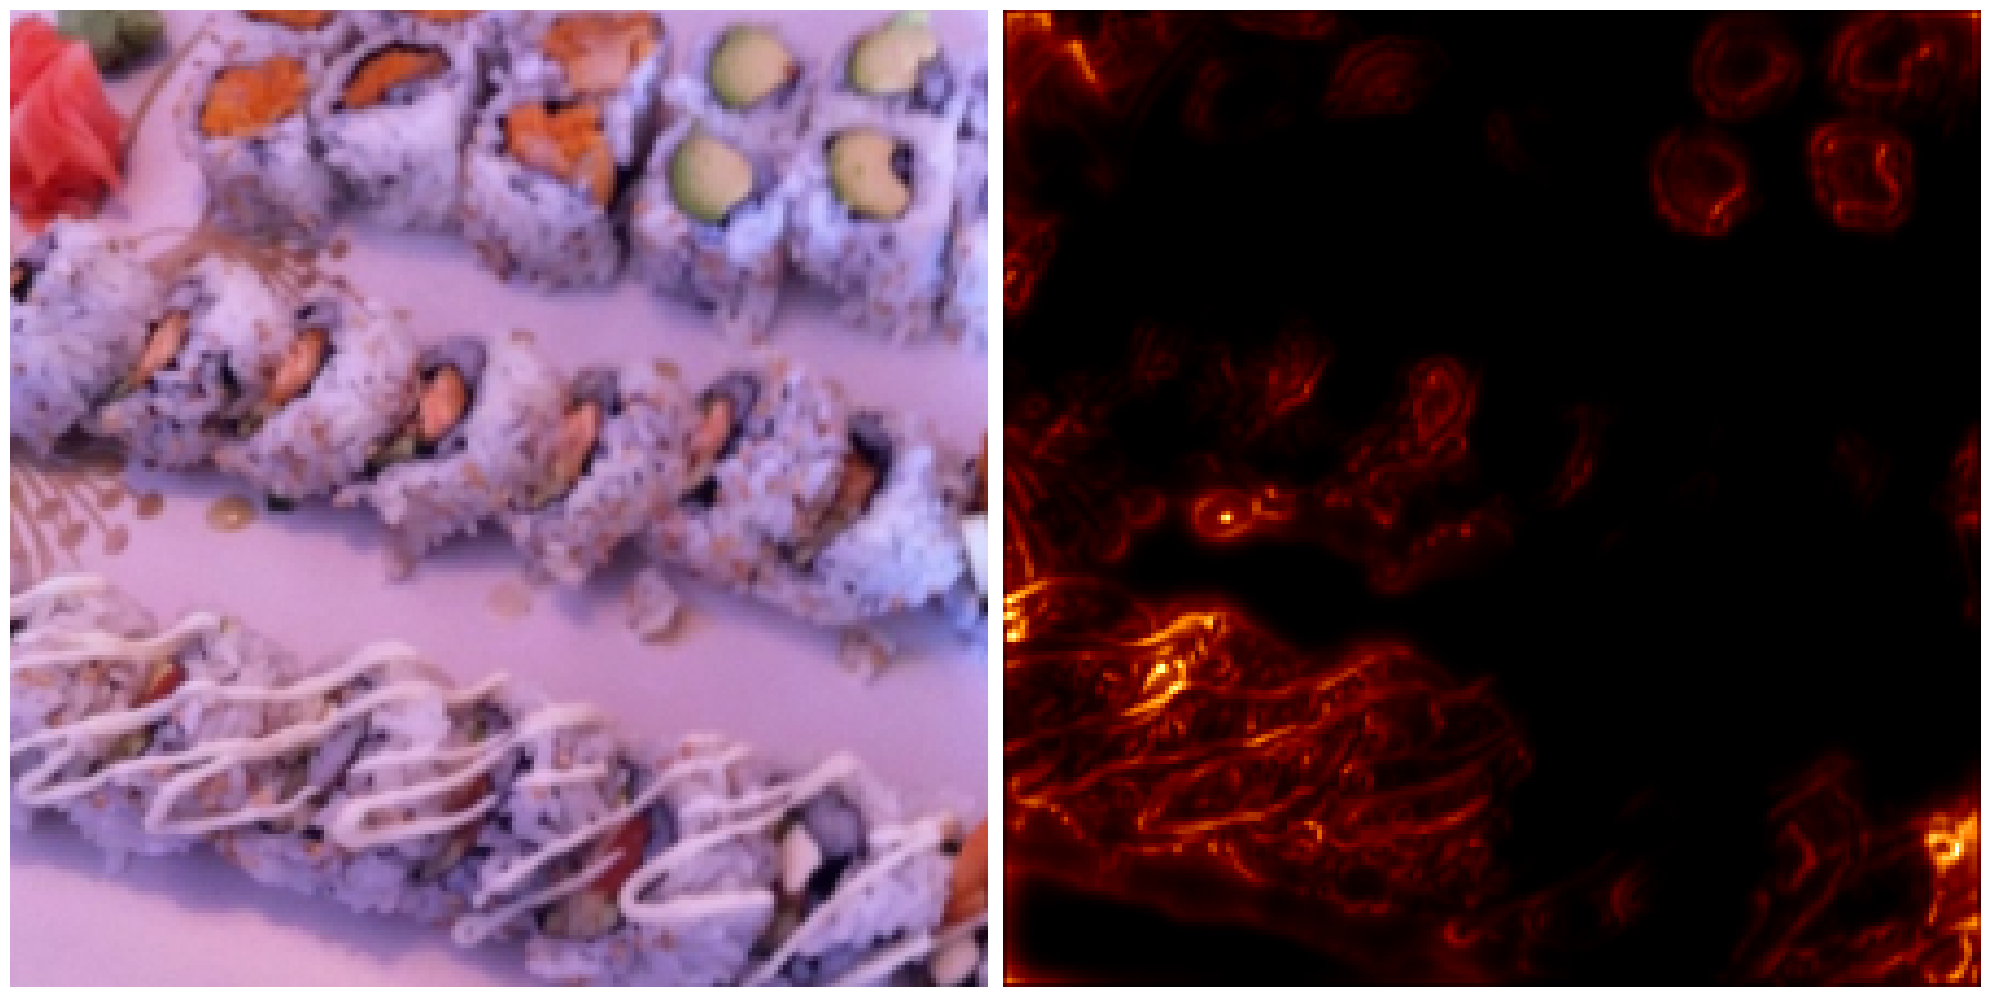

Displaying: ./output/image_174.png


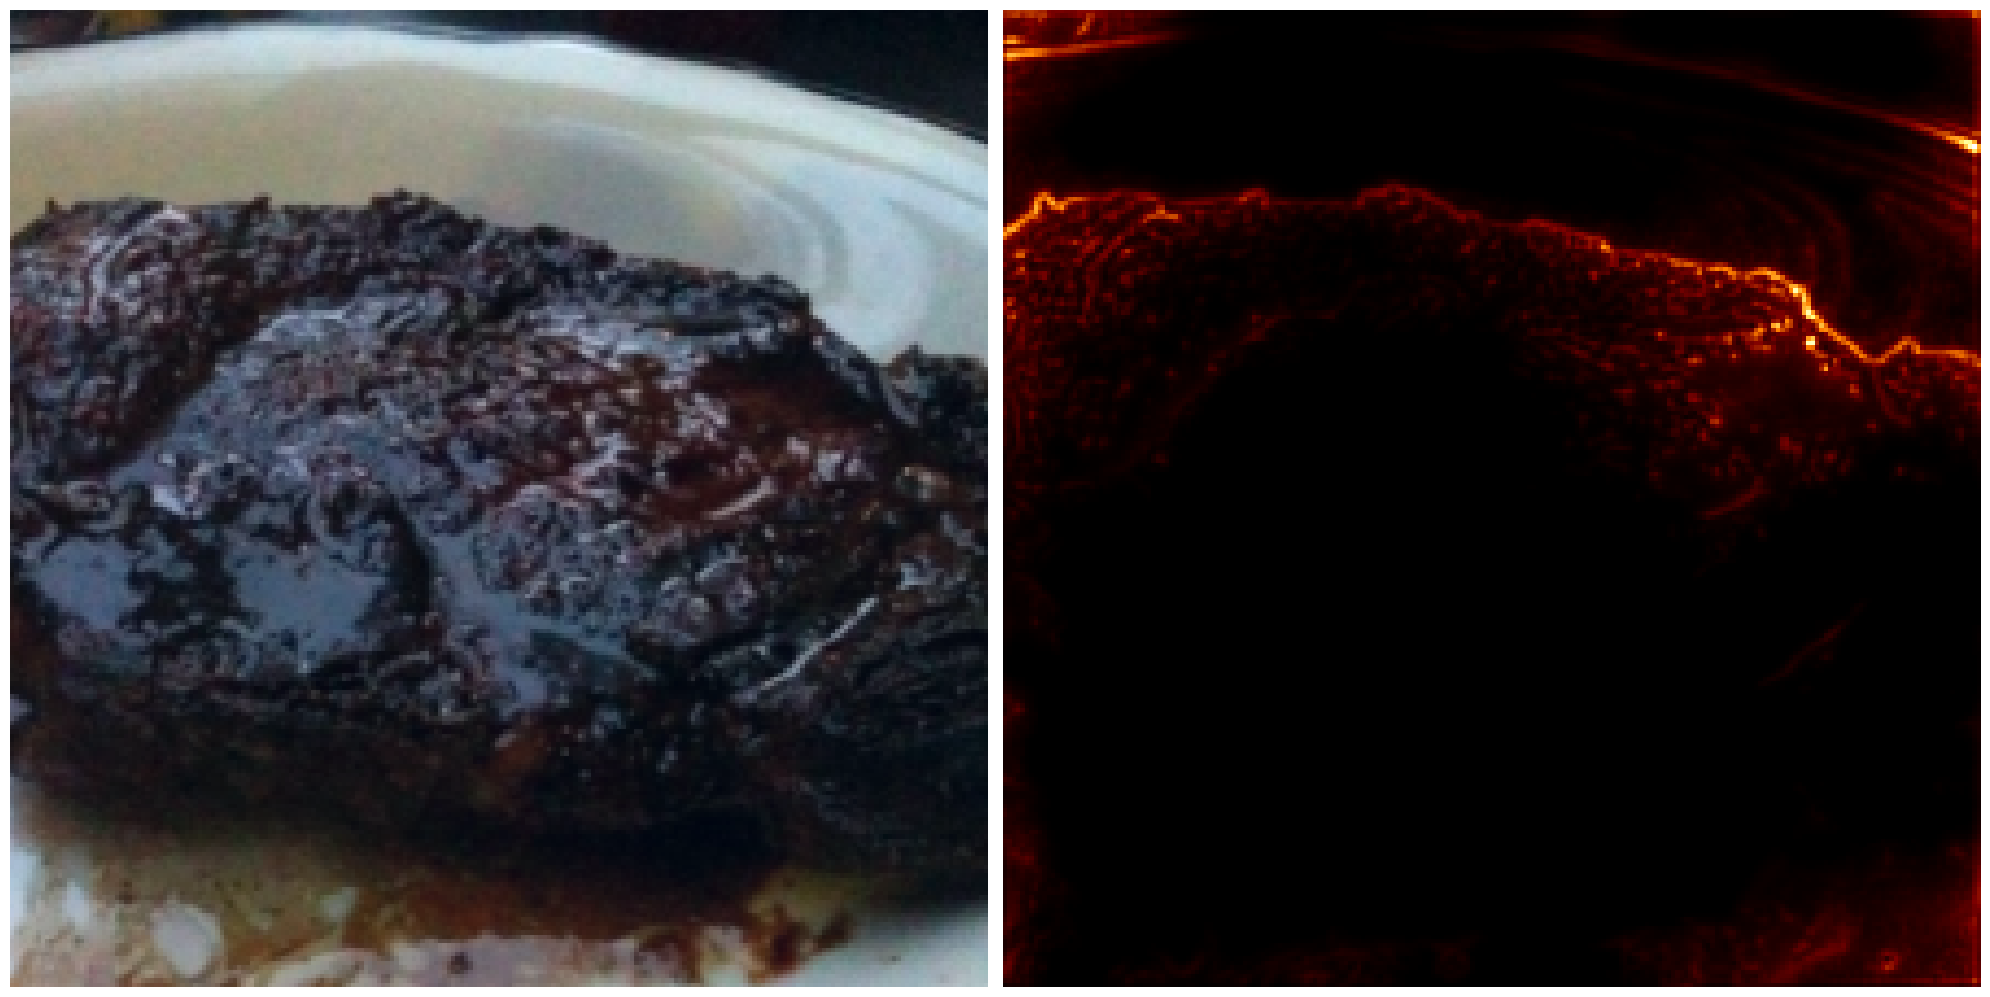

Displaying: ./output/image_30.png


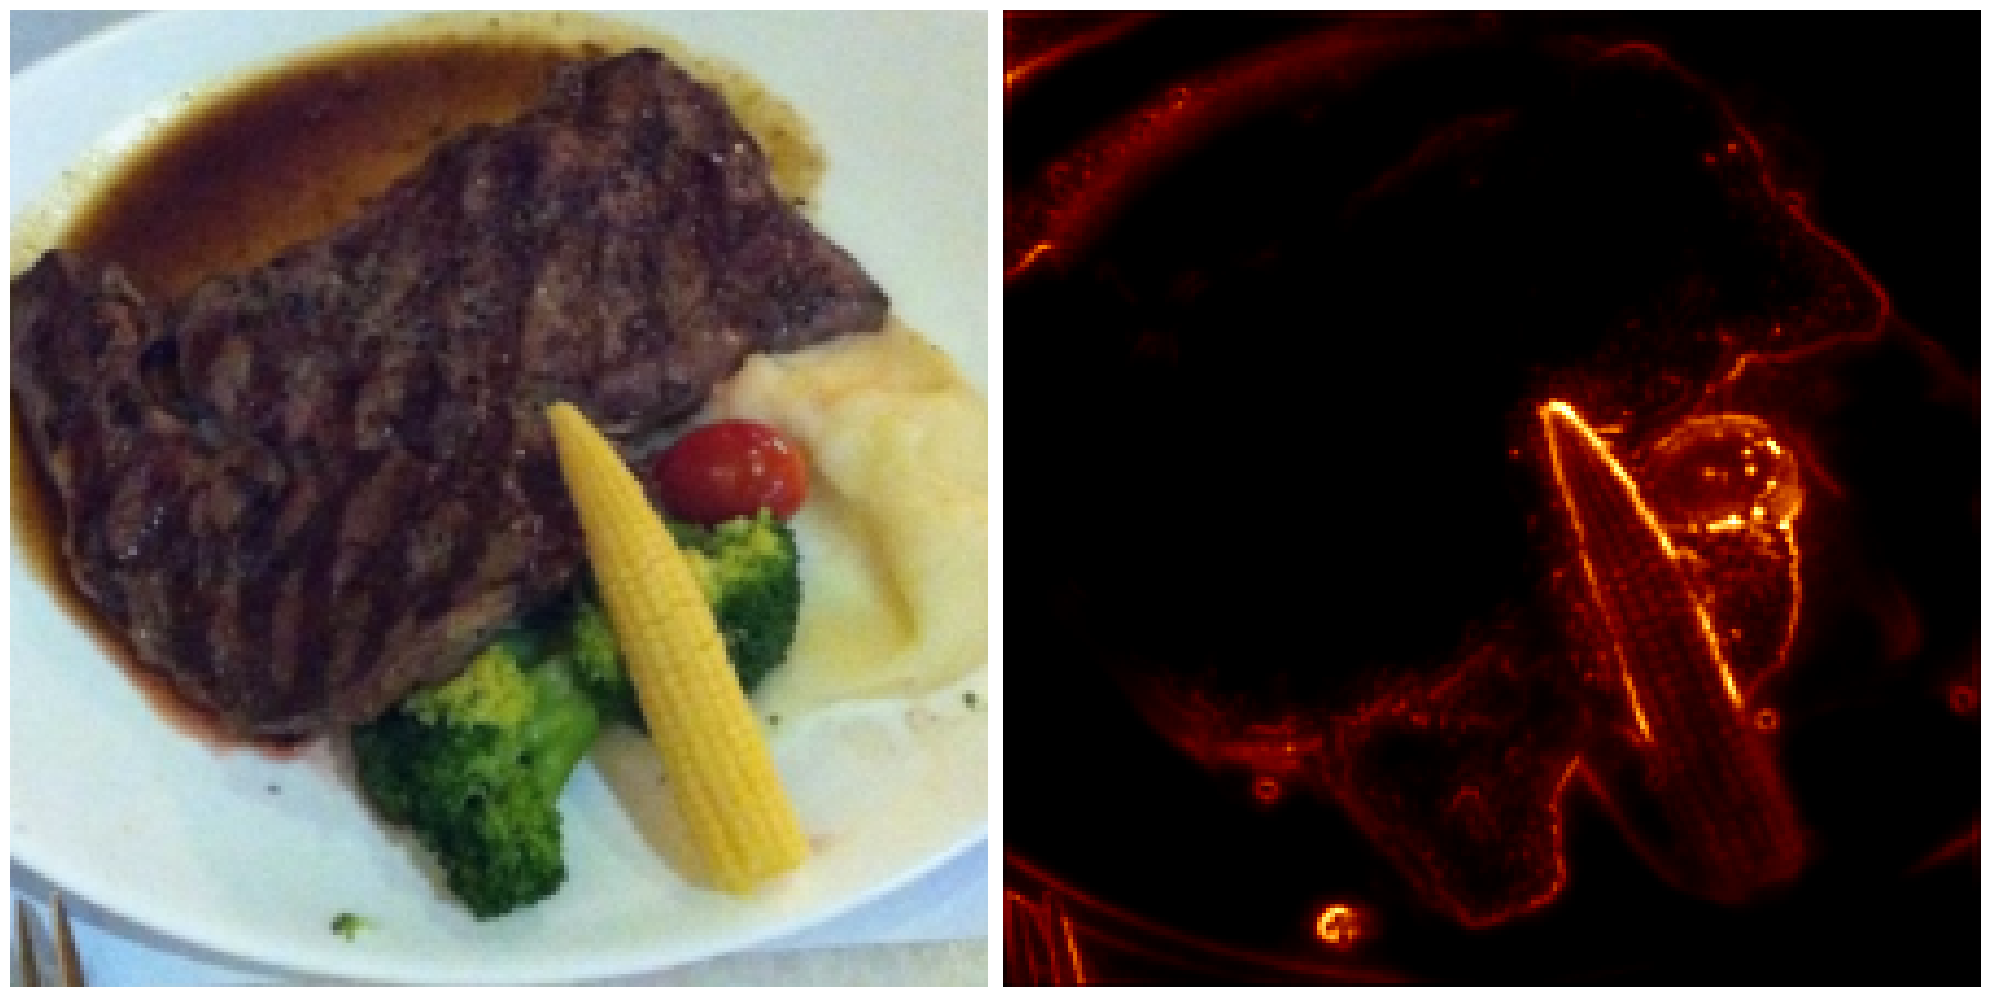

Displaying: ./output/image_109.png


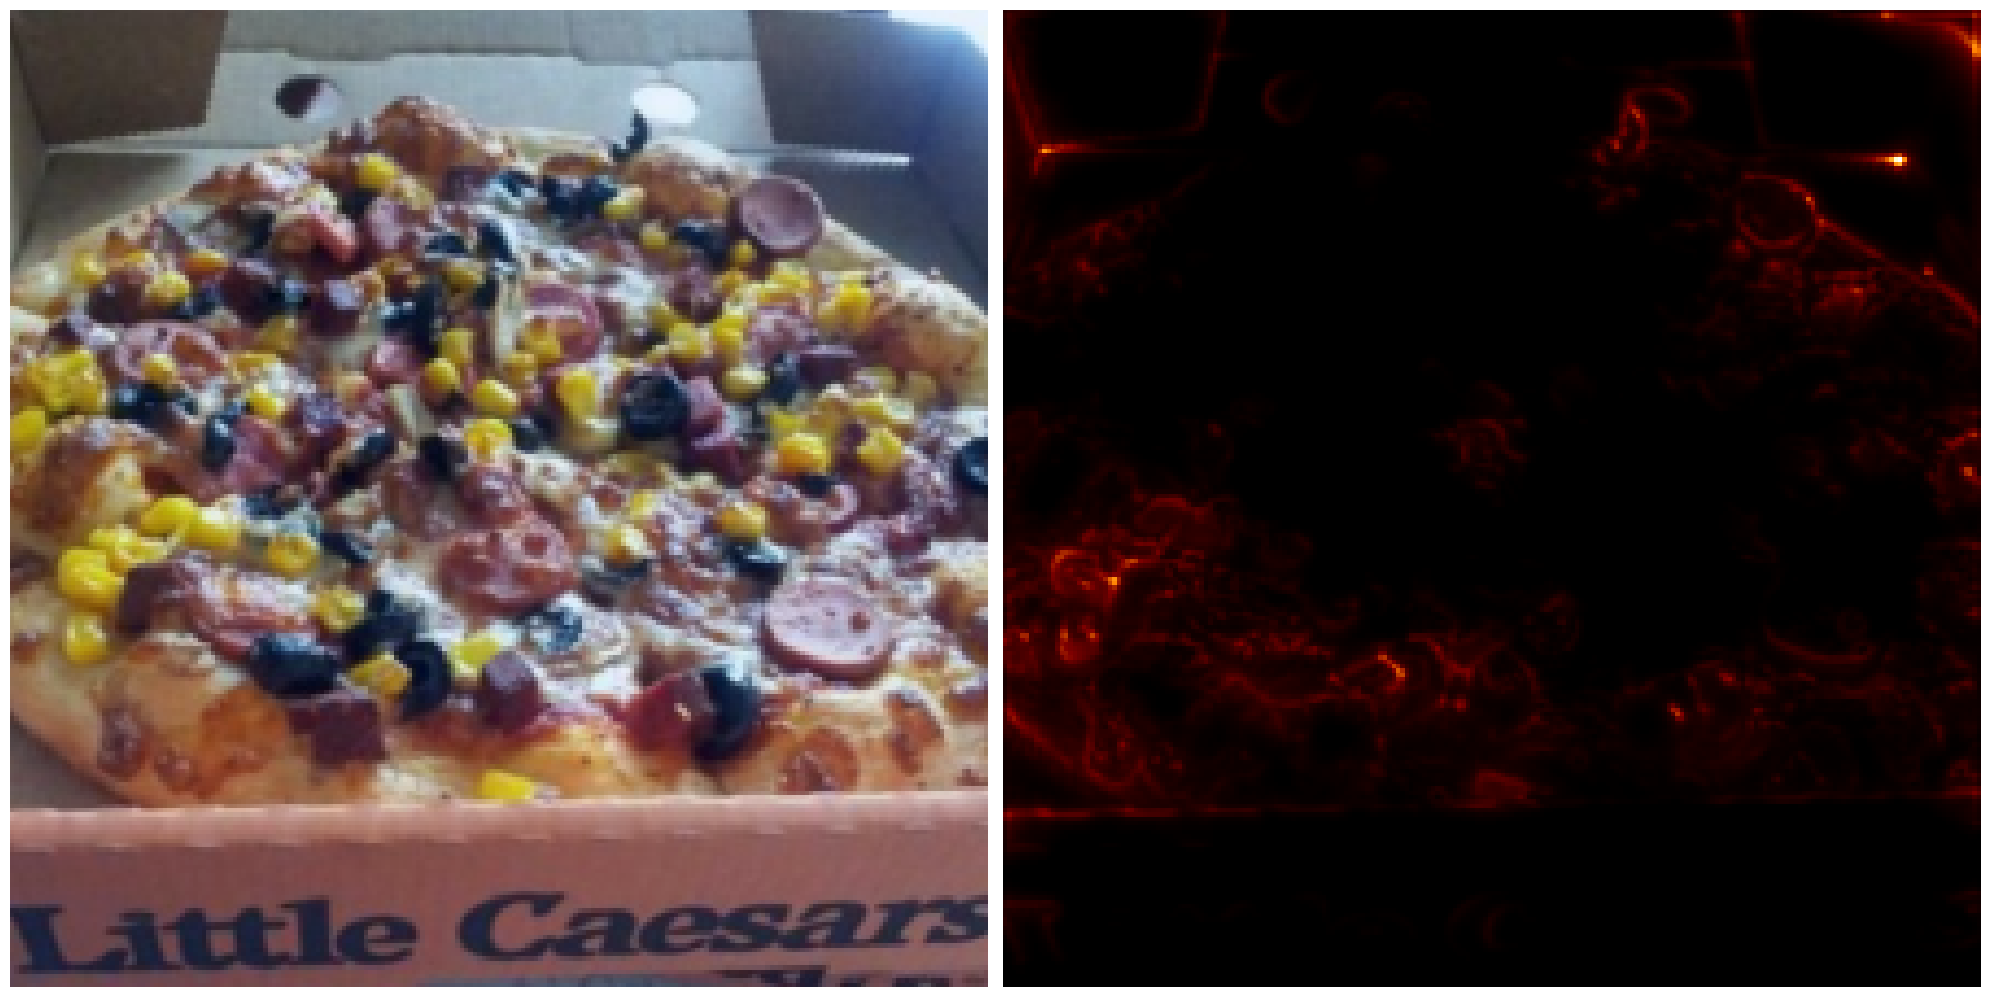

Displaying: ./output/image_91.png


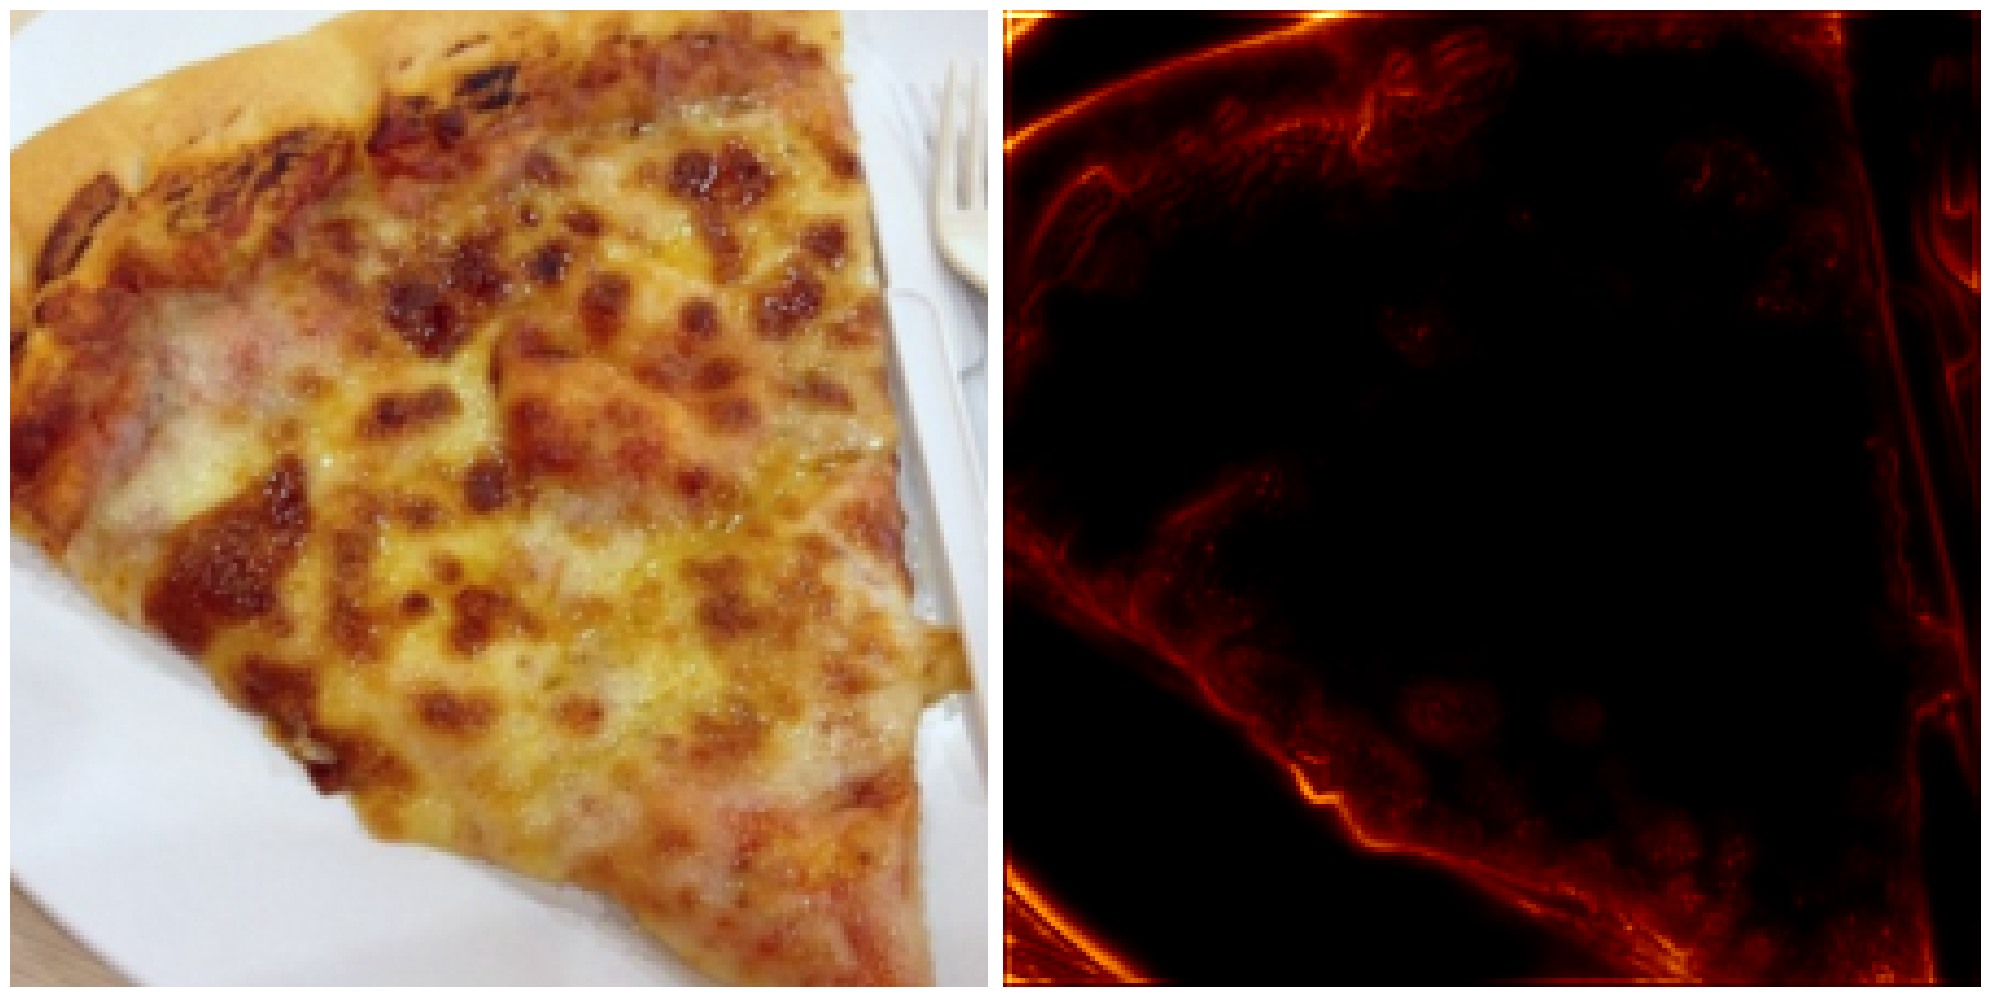

Displaying: ./output/image_139.png


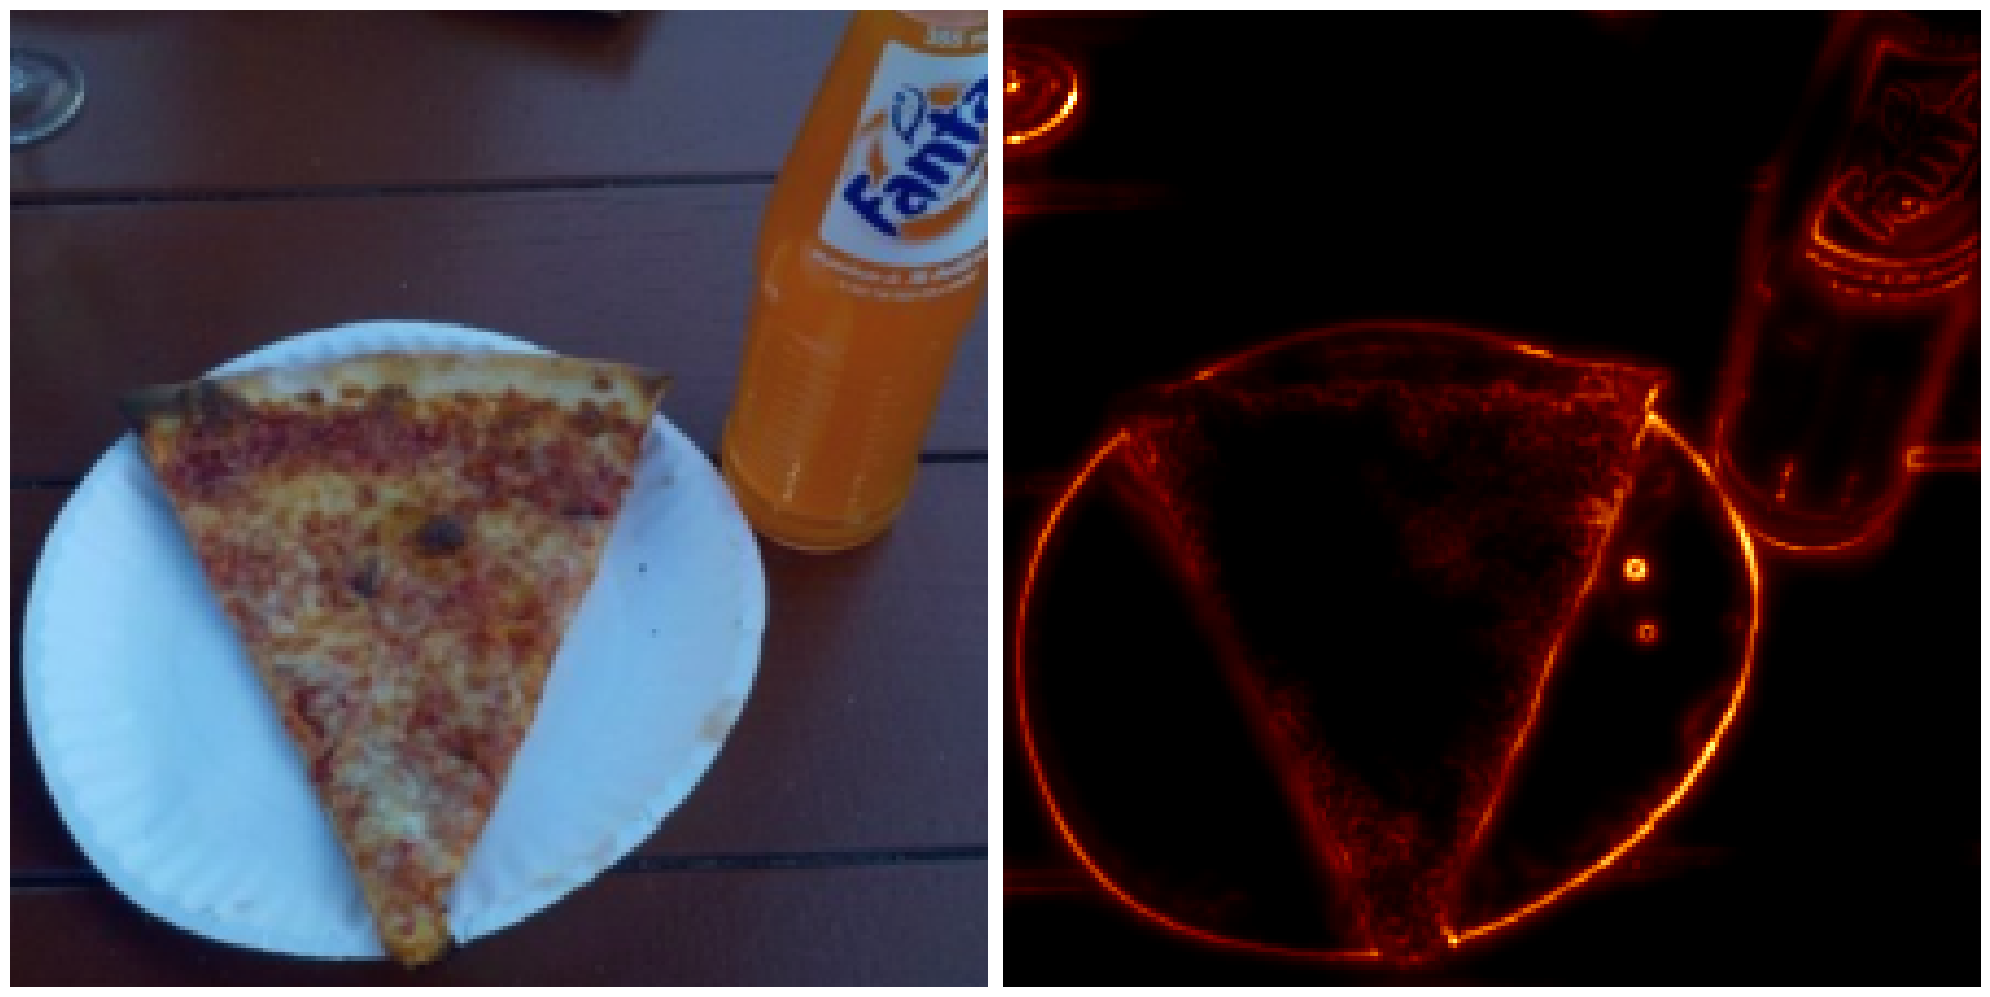

Displaying: ./output/image_278.png


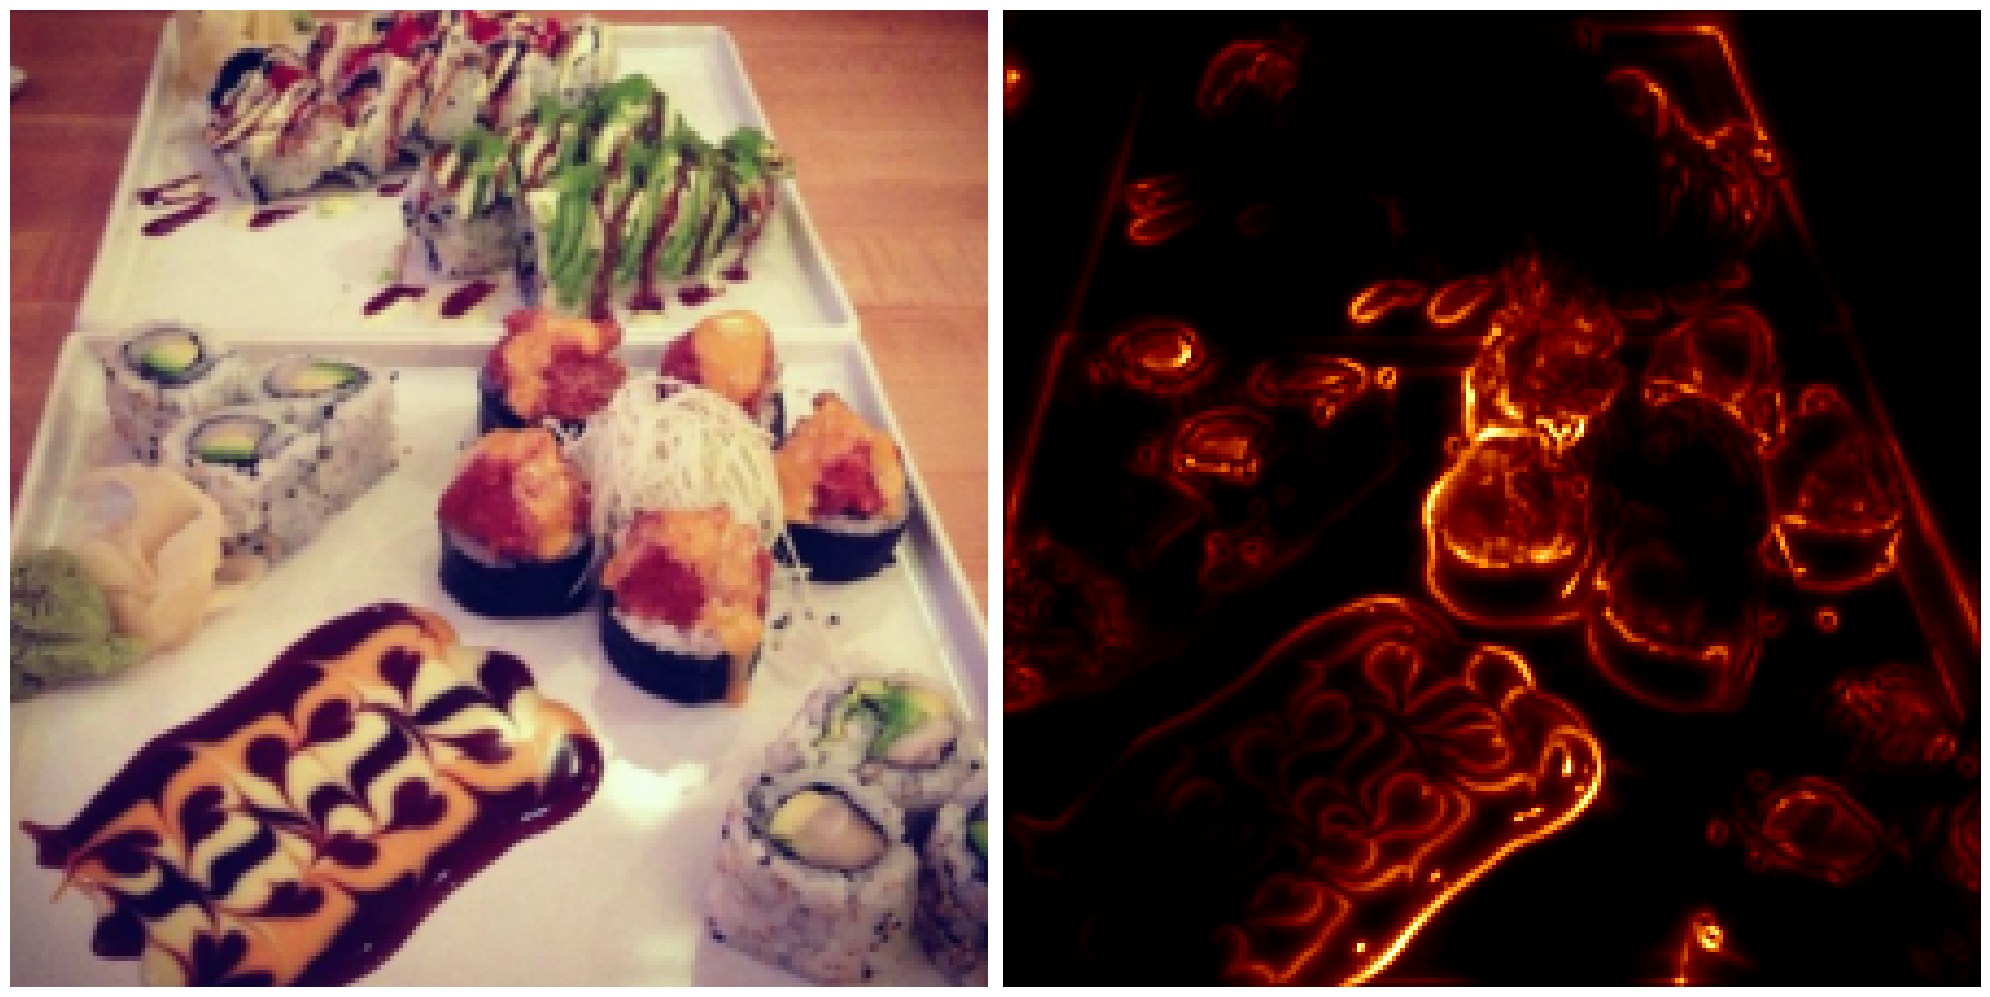

Displaying: ./output/image_214.png


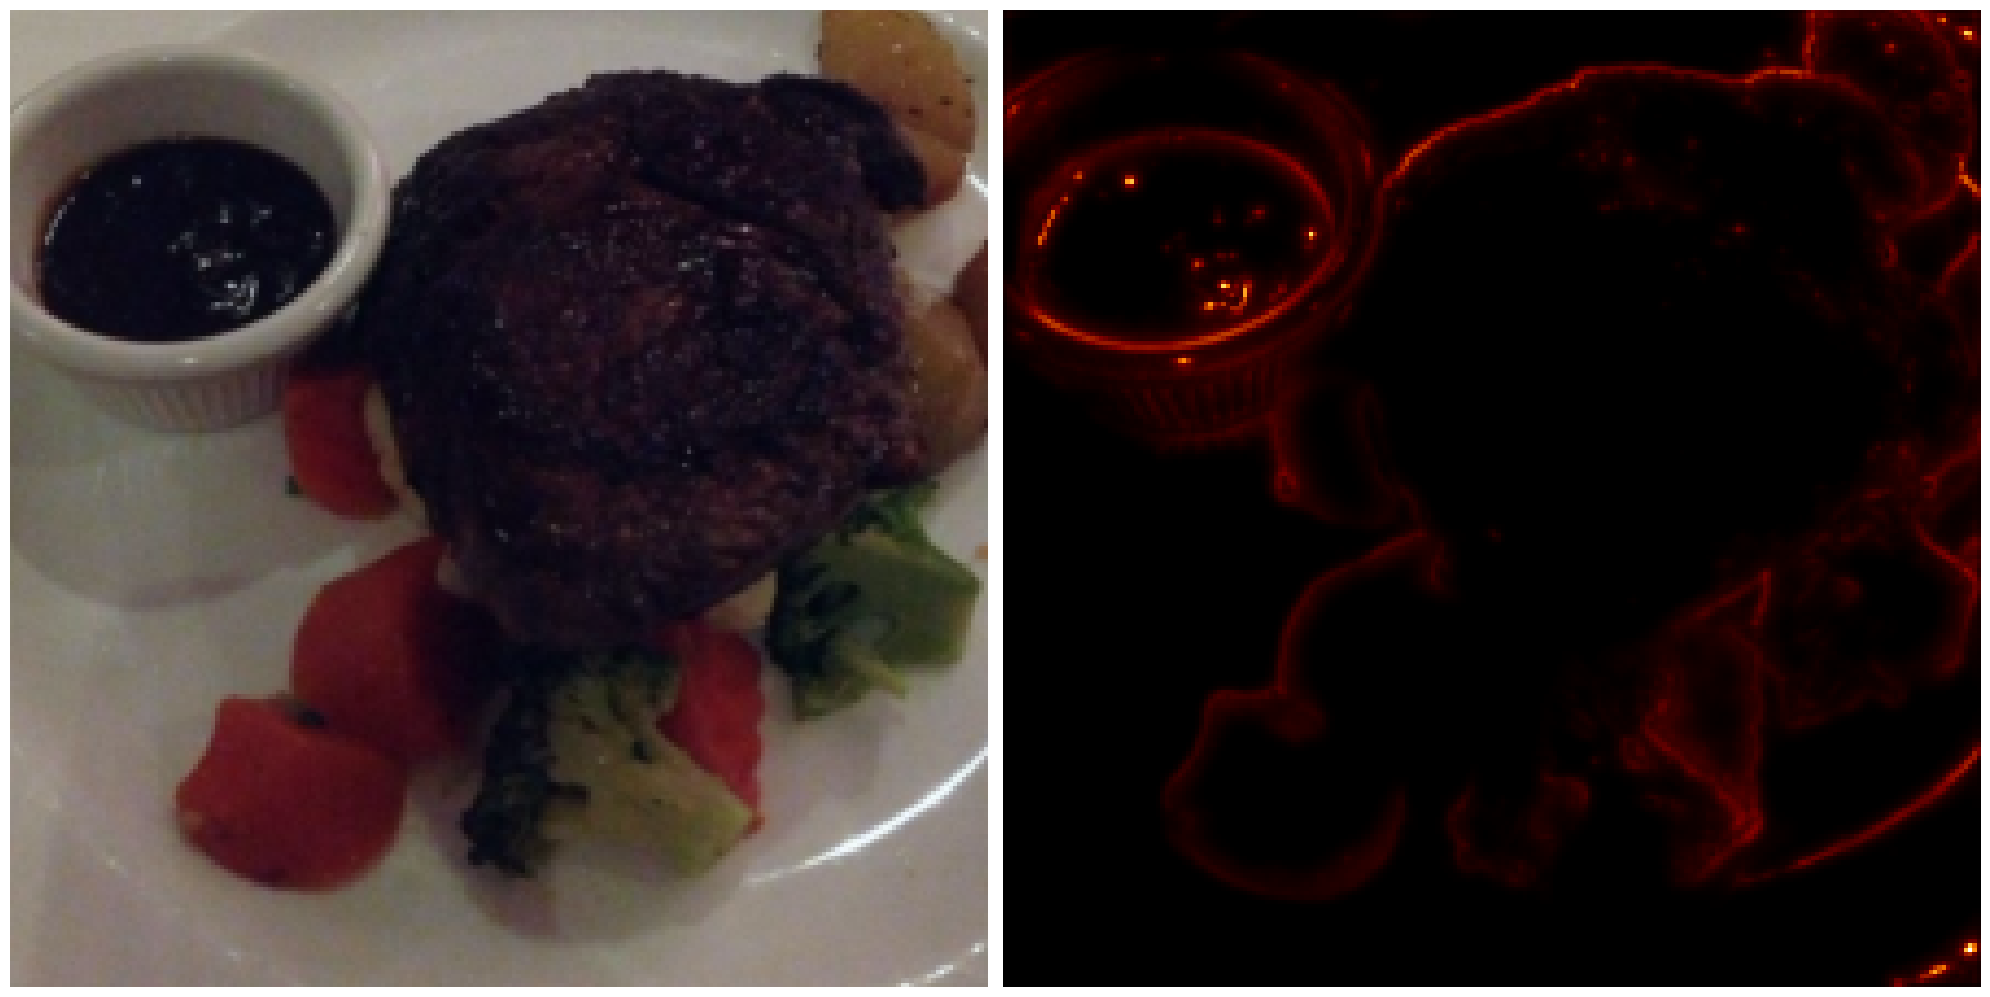

Displaying: ./output/image_2.png


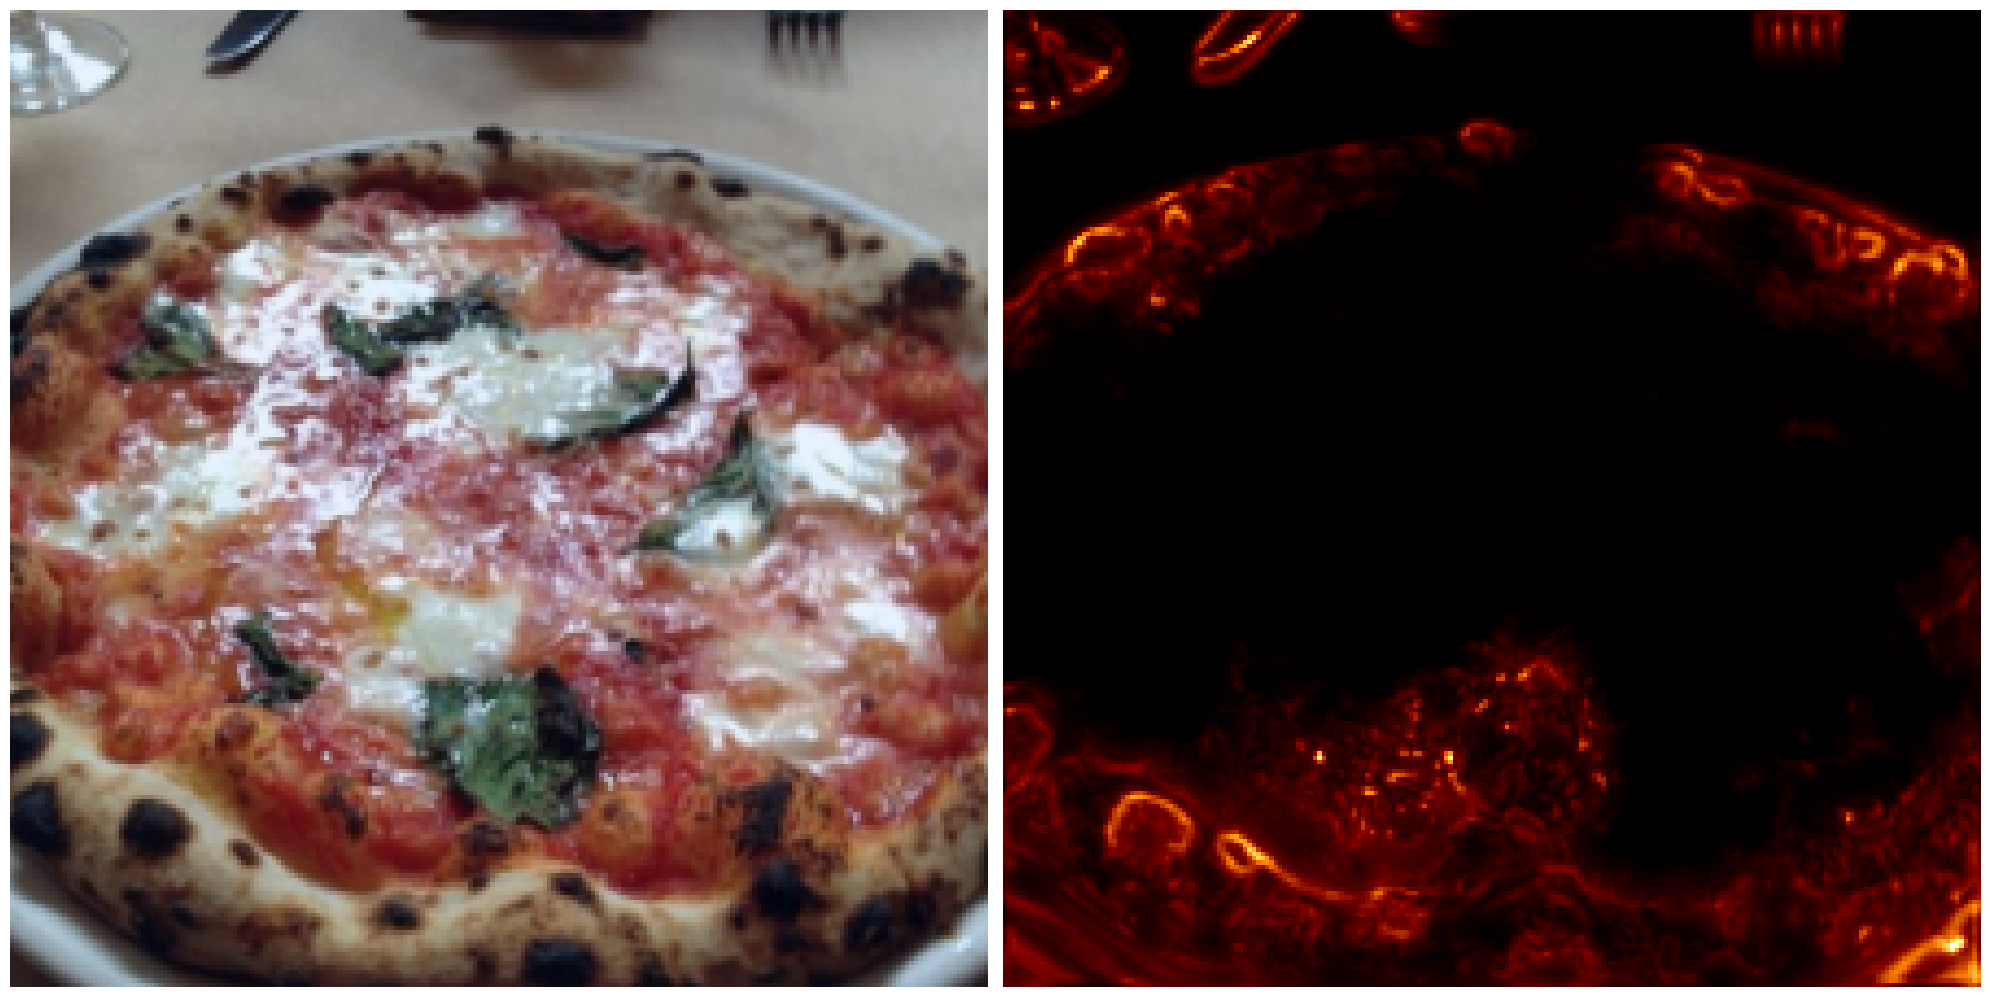

In [ ]:
from IPython.display import Image, display
import os
from random import randint

x = []
for p in range(10):
  x.append(randint(0, 299))
print(x)

output_dir = "./output"

for i in range(10):
    img_path = os.path.join(output_dir, f"image_{x[i]}.png")

    if os.path.exists(img_path):
        print(f"Displaying: {img_path}")
        display(Image(filename=img_path))
    else:
        print(f"Could not find: {img_path}")

#5. Save output

In [ ]:
import shutil

source_path = '/content/output'
destination_path = '/content/drive/MyDrive/study/Project/clean_heatmap'
shutil.copytree(source_path, destination_path, dirs_exist_ok=True)

print("Folder saved to drive")

Folder saved to drive
